# 07. 가설 검증 — 고립은 노년만의 문제인가


| 단계 | 노트북 | 질문 |
|---|---|---|
| 00 | 프로젝트 개요 | 무엇을, 왜, 어떤 순서로 하는가 |
| 01 | 데이터 준비 · 품질 점검 | 받은 데이터를 그대로 믿고 써도 되는가 |
| 02 | 탐색 분석 — 고립 신호 | 데이터에서 연령·성별·지역별 고립 신호 후보가 보이는가 |
| 03 | 외부 데이터 결합 · 검증 | 그 신호를 공식 기준·외부 요인·정답 데이터로 검증하면 무엇이 남는가 |
| 04 | **위험도 2축 모델 (주 모델)** | 정답 없이 만든 '행동 고립 × 사회경제 취약' 위험도가 실행 전에 정한 독립 기준을 통과하는가 |
| 05 | 복지자원 매핑 | 위험 유형 × 생애단계에 연계할 복지서비스가 실제로 있는가 |
| 06 | AI 에이전트 설계 | 탐지→판단→원인→추천→우선 대상을 어떻게 운영하고, 실제 고립과 어떻게 연결하는가 |
| 07 | 가설 검증 — 고립은 노년만의 문제인가 | 청년·중년에도 노년 이상인 고립 위험 요인이 있는가 (사전 등록 판정) |
| 부록 A | 학습형 비교 모델 (이전 04) | SKT 정답으로 학습하면 어디까지 맞히는가 · 실시간 단계 조정 규칙 T |
| 부록 B | 지수형 첫 검증 (이전 04b) | 정답 없이 만든 지수가 학습형만큼 맞히고 독립 지표와도 맞는가 |

> **이전 단계에서 온 것**: 02의 연령별 신호, 03의 공식 고립률, 04의 주민등록 지표, 05의 서비스 공급  
> **이 노트북에서 할 것**: '고립은 노년만의 문제가 아니다'를 가설로 세우고, 실행 전에 고정한 기준과 연령 간 절대 수준 지표로 판정합니다.  
> **다음 단계로 넘길 것**: 가설 판정(부분 지지)과 연령별 고립 유형의 차이 → README·보고서의 문제 제기

**질문**: "고립은 노년만의 문제가 아니다"는 데이터로도 확인되는가?

이 프로젝트는 처음부터 전 연령을 분석했습니다. 이 노트북은 그 출발점을 **가설로 세우고, 실행 전에 고정한 기준으로 판정**합니다.

## 1. 배경 — 왜 이 가설을 세웠나

> **왜** 전 연령 분석은 주장이 아니라 확인할 가설이어야 하므로, 가설의 배경을 먼저 밝힙니다.  
> **결과** 고립·은둔 청년 54만 명(복지부 추정), 고독사 사망자 중 50·60대 남성 53.9%, 19~29세 고립도 24.4%를 배경으로 삼았습니다.


| 배경 | 내용 | 출처 |
|---|---|---|
| 청년 | 보건복지부는 고립·은둔 청년을 청년 인구의 약 5%, **54만 명**으로 추정했습니다 (2022 청년 삶 실태조사 기반). | [뉴시스, "'54만명 추정' 고립·은둔 청년, 국가가 나선다" (2023.12.13)](https://www.newsis.com/view/NISX20231213_0002556536) |
| 중년 | 2023년 고독사 사망자 3,661명 중 **50·60대 남성이 53.9%**입니다. | [이투데이 (보건복지부 고독사 실태조사 보도)](https://www.etoday.co.kr/news/view/2410394) |
| 공식 통계 | 사회적 고립도는 60세 이상 39.4%로 가장 높지만, 19~29세도 24.4%입니다. | [통계청 국가지표체계](https://www.index.go.kr/unify/idx-info.do?idxCd=8080) |

정책과 인식은 여전히 '독거노인' 중심이지만, 위 자료는 청년·중년에도 고립 위험이 크다는 것을 보여 줍니다. 우리 지역(강남·춘천)의 데이터로도 그런지 확인합니다.

## 2. 가설과 판정 기준 (실행 전 고정)

> **왜** 결과를 보고 기준을 고르지 않도록 가설과 판정 규칙을 실행 전에 고정합니다.  
> **결과** 판정 지표 10개, 지표별 위험 방향, 종합 판정 규칙(7개+ 지지, 1~6개 부분 지지)을 사전 등록 파일에서 읽었습니다. 연령 안 백분위로 만든 04 유형 비중은 근거에서 뺐습니다.


In [1]:
import warnings, json, re; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False})
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 220)
DATA, EXT, OUTD = Path('csv'), Path('external'), Path('outputs')
MAIN = ['서울 강남구', '강원 춘천시']; AGE5 = ['20대', '30대', '40대', '50대', '60대+']
STAGE = {'20대': '청년', '30대': '청년', '40대': '중년', '50대': '중년', '60대+': '노년'}
STAGE_C = {'청년': '#2a78d6', '중년': '#1baf7e', '노년': '#eb6834'}
PRE = json.load(open(OUTD / '가설_전연령고립_사전등록.json', encoding='utf-8'))
FROZEN = json.load(open(OUTD / '모델설정_동결.json', encoding='utf-8'))
for k in ['가설', '판정 규칙']:
    print(f'[{k}]'); [print(f'  {a}: {b}') for a, b in PRE[k].items()]
def a5(a): return '60대+' if a >= 60 else (f'{a // 10 * 10}대' if a >= 20 else None)

[가설]
  H0: 고립 위험 요인은 노년(60대+)에 집중되어, 청년(20~30대)과 중년(40~50대)은 모든 지표에서 노년보다 위험이 낮다.
  H1: 청년 또는 중년에서도 고립 위험 요인이 노년과 같거나 더 높은 지표가 존재한다.
[판정 규칙]
  지표별: 청년 또는 중년 중 한 연령대라도 위험 방향으로 노년과 같거나 더 나쁘면 'H1 성립'
  종합: 판정 지표 10개 중 2/3 이상(7개+) 성립 → '지지', 1~6개 → '부분 지지', 0개 → '기각'
  보고: 노년이 더 높은 지표(H1 불성립)도 모두 그대로 보고


**근거로 쓰지 않는 것**
- 04의 위험 유형 비중(예: 20대 이중 위험 23~24%)은 쓰지 않습니다. H·V를 **같은 성·연령 안의 백분위**로 만들었기 때문에, 어느 연령이든 상위권 비중이 기계적으로 비슷하게 나옵니다. 이 값으로 "청년도 노년만큼 위험하다"고 하면 순환 논리입니다(6절에서 확인).
- 서울 관심집단 비율도 쓰지 않습니다. 연령대마다 상위 2%로 정의되어 있어 연령 간 수준을 비교할 수 없습니다.

→ **연령 간 절대 수준**을 비교할 수 있는 지표만 씁니다.

## 3. 증거 지표 계산

> **왜** 연령 간 절대 수준을 비교할 수 있는 지표만 모읍니다.  
> **결과** 공식 고립도, 혼자 사는 비율, 심야·외부활동 소비 비중, 소비 참여도, 고독사 위험군 규모를 연령별로 계산했습니다.


In [2]:
%%time
E = []                                                   # 행: 지표 × 지역 × 연령
def add(key, region, name, direction, vals, src):
    for a, v in vals.items(): E.append({'지표': key, '지역': region, '내용': name, '위험 방향': direction, '연령': a, '값': float(v), '출처': src})
# E1 공식 사회적 고립도 (전국)
add('E1', '전국', '공식 사회적 고립도(%)', '높을수록', FROZEN['기본위험 B(연령별 %)'], '국가지표체계 사회적 고립도(국가데이터처): 19~29세·60세 이상 원문, 30~50대 보도 인용')
# E2 혼자 사는 비율 (주민등록 2024.12)
CODES = pd.read_csv(EXT / 'codes/읍면동_코드대응표_강남_춘천.csv', dtype=str)
K2R = dict(zip(CODES['행정기관코드'], CODES['지역']))
def mois(kind):
    d = pd.read_csv(EXT / f'mois/행정동_성연령별_{kind}_20241231.csv', encoding='cp949', dtype=str)
    d['지역'] = d['행정구역'].str.extract(r'\((\d{10})\)')[0].map(K2R); d = d.dropna(subset=['지역'])
    cols = [c for c in d.columns if re.search(r'_(남|여)_\d', c)]
    L = d.melt(id_vars='지역', value_vars=cols, var_name='col', value_name='n')
    L['n'] = pd.to_numeric(L['n'].str.replace(',', '')); L['성별'] = L['col'].str.extract(r'_(남|여)_')[0]
    L['연령5'] = L['col'].str.extract(r'_(남|여)_(\d+)')[1].astype(int).map(a5)
    return L.dropna(subset=['연령5'])
pop, one = mois('주민등록인구'), mois('1인세대수')
alone = (one.groupby(['지역', '연령5'])['n'].sum() / pop.groupby(['지역', '연령5'])['n'].sum() * 100)
alone_sex = (one.groupby(['지역', '성별', '연령5'])['n'].sum() / pop.groupby(['지역', '성별', '연령5'])['n'].sum() * 100)
for r in MAIN: add('E2', r, '혼자 사는 비율(%)', '높을수록', alone[r], '주민등록 2024.12')
# E3 카드 (법인·특수 업종 제외, 04와 같은 정의)
REN = {'기준일자': '일자', '가맹점 위치정보(시·군·구)': '지역', '가맹점 업종': '업종', '이용고객 성별': '성별', '이용고객 연령대': '연령대', '결제건수 합계': '건수'}
EXCL = ['ZZ_나머지', '세금공과금', '보험', '상품권/복권', '통신요금(이동,시내전화)', '통신요금(PC통신,무선호출)', '학교등록금', '결제대행(PG)']
OUTD_ = ['한식', '양식', '일식', '중식', '기타요식', '패스트푸드', '제과점', '커피전문점', '노래방', '영화/공연', '게임방/오락실', '종합레저타운/놀이동산',
         '스포츠시설', '헬스장', '실내/실외골프장', '싸우나/목욕탕', '유흥업소', '주류판매', '여행사/항공사', '호텔/콘도', '고속버스/철도/여객선', '택시']
card = pd.read_csv(DATA / '신한카드_데이터1_시간대별.csv', usecols=list(REN) + ['시간대']).rename(columns=REN)
card = card[(card['성별'] != '법인') & ~card['업종'].isin(EXCL)]
card['연령5'] = card['연령대'].str.replace(' ', '').map(lambda a: None if a == '10대' else ('60대+' if a in ('60대', '70대', '80대', '90대') else a))
card = card.dropna(subset=['연령5']); k = ['지역', '연령5']; base = card.groupby(k)['건수'].sum()
night = card[card['시간대'] == '00_05'].groupby(k)['건수'].sum() / base * 100
outdoor = card[card['업종'].isin(OUTD_)].groupby(k)['건수'].sum() / base * 100
age = pd.read_csv(DATA / 'SK_유동인구_성연령.csv', dtype={'소지역코드': str})
age['지역'] = age['소지역코드'].str[:8].map(dict(zip(CODES['SGIS코드'], CODES['지역']))); age = age.dropna(subset=['지역'])
SKA = ['10대', '20대', '30대', '40대', '50대', '60대+']; MC = [c for c in age.columns if c.startswith('남자')]; FC = [c for c in age.columns if c.startswith('여자')]
flow_ = pd.concat({a: age.groupby('지역')[[MC[i], FC[i]]].sum().sum(axis=1) for i, a in enumerate(SKA) if a != '10대'}, names=['연령5']).swaplevel().sort_index()
part = (base / base.groupby('지역').transform('sum')) / (flow_ / flow_.groupby('지역').transform('sum'))
for r in MAIN:
    add('E3a', r, '심야(00~05시) 소비 비중(%)', '높을수록', night[r], '신한카드')
    add('E3b', r, '외부활동 소비 비중(%)', '낮을수록', outdoor[r], '신한카드')
    add('E3c', r, '소비 참여도(카드 비중 ÷ 유동 비중)', '낮을수록', part[r], '신한카드 + SK')
# E4 고독사 위험군 규모 (복지부 기본계획 14쪽: 50대 37.3만, 60대 35.5만. 70대 이상 21만은 10세 폭이 달라 사전 등록대로 비교에서 뺌)
add('E4', '전국', '고독사 위험군 규모(만 명, 50대 vs 60대)', '높을수록', {'50대': 37.3, '60대+': 35.5}, '보건복지부 제1차 고독사 예방 기본계획(2023.5.18) 14쪽')
E = pd.DataFrame(E)
TAB = E.pivot_table(index=['지표', '지역', '내용', '위험 방향'], columns='연령', values='값').reindex(columns=AGE5)
TAB.round(2)

CPU times: total: 4.45 s
Wall time: 4.55 s


연령                                              20대    30대    40대    50대   60대+
지표  지역     내용                          위험 방향                                   
E1  전국     공식 사회적 고립도(%)               높을수록   24.40  26.50  29.50  37.20  39.40
E2  강원 춘천시 혼자 사는 비율(%)                 높을수록   32.41  24.82  15.10  18.76  27.67
    서울 강남구 혼자 사는 비율(%)                 높을수록   25.58  35.51  17.01  12.97  18.49
E3a 강원 춘천시 심야(00~05시) 소비 비중(%)         높을수록    6.49   3.18   1.97   2.04   1.21
    서울 강남구 심야(00~05시) 소비 비중(%)         높을수록    5.23   5.40   4.57   3.46   2.05
E3b 강원 춘천시 외부활동 소비 비중(%)               낮을수록   39.68  36.70  34.76  34.64  28.56
    서울 강남구 외부활동 소비 비중(%)               낮을수록   35.81  30.52  23.39  25.12  23.51
E3c 강원 춘천시 소비 참여도(카드 비중 ÷ 유동 비중)       낮을수록    1.02   1.58   1.11   1.02   0.60
    서울 강남구 소비 참여도(카드 비중 ÷ 유동 비중)       낮을수록    0.84   1.26   1.19   1.05   0.61
E4  전국     고독사 위험군 규모(만 명, 50대 vs 60대) 높을수록     NaN    NaN    NaN  37.30  35.50

## 4. 판정 — 지표마다 '청년·중년 중 노년과 같거나 더 위험한 연령대가 있는가'

> **왜** 지표마다 청년·중년 중 노년과 같거나 더 위험한 연령대가 있는지 봅니다.  
> **결과** 10개 중 6개에서 성립 → 부분 지지. 혼자 사는 비율·심야 소비·고독사 위험군은 청년·중년이 노년 이상이고, 공식 고립도·소비 참여도는 노년이 가장 취약합니다.


In [3]:
rows = []
for (key, reg, name, d), r in TAB.iterrows():
    elder = r['60대+']; others = r.drop('60대+').dropna()
    worse = others[others >= elder] if d == '높을수록' else others[others <= elder]
    rows.append({'지표': key, '지역': reg, '내용': name, '위험 방향': d, '노년(60대+)': round(elder, 2),
                 '청년·중년 중 가장 위험한 값': round((others.max() if d == '높을수록' else others.min()), 2),
                 '노년 이상인 연령대': ', '.join(worse.index) or '—', 'H1 성립': len(worse) > 0})
J = pd.DataFrame(rows)
n_ok, n = int(J['H1 성립'].sum()), len(J)
verdict = '지지' if n_ok >= int(np.ceil(n * 2 / 3)) else ('부분 지지' if n_ok >= 1 else '기각')
display(J)
print(f'판정 지표 {n}개 중 H1 성립 {n_ok}개 → 종합 판정: {verdict}')
J.assign(종합판정=verdict).to_csv(OUTD / '가설검증_전연령고립.csv', index=False, encoding='utf-8-sig')

,지표,지역,내용,위험 방향,노년(60대+),청년·중년 중 가장 위험한 값,노년 이상인 연령대,H1 성립
0,E1,전국,공식 사회적 고립도(%),높을수록,39.40,37.20,—,False
1,E2,강원 춘천시,혼자 사는 비율(%),높을수록,27.67,32.41,20대,True
2,E2,서울 강남구,혼자 사는 비율(%),높을수록,18.49,35.51,"20대, 30대",True
3,E3a,강원 춘천시,심야(00~05시) 소비 비중(%),높을수록,1.21,6.49,"20대, 30대, 40대, 50대",True
4,E3a,서울 강남구,심야(00~05시) 소비 비중(%),높을수록,2.05,5.40,"20대, 30대, 40대, 50대",True
5,E3b,강원 춘천시,외부활동 소비 비중(%),낮을수록,28.56,34.64,—,False
6,E3b,서울 강남구,외부활동 소비 비중(%),낮을수록,23.51,23.39,40대,True
7,E3c,강원 춘천시,소비 참여도(카드 비중 ÷ 유동 비중),낮을수록,0.60,1.02,—,False
8,E3c,서울 강남구,소비 참여도(카드 비중 ÷ 유동 비중),낮을수록,0.61,0.84,—,False
9,E4,전국,"고독사 위험군 규모(만 명, 50대 vs 60대)",높을수록,35.50,37.30,50대,True


판정 지표 10개 중 H1 성립 6개 → 종합 판정: 부분 지지


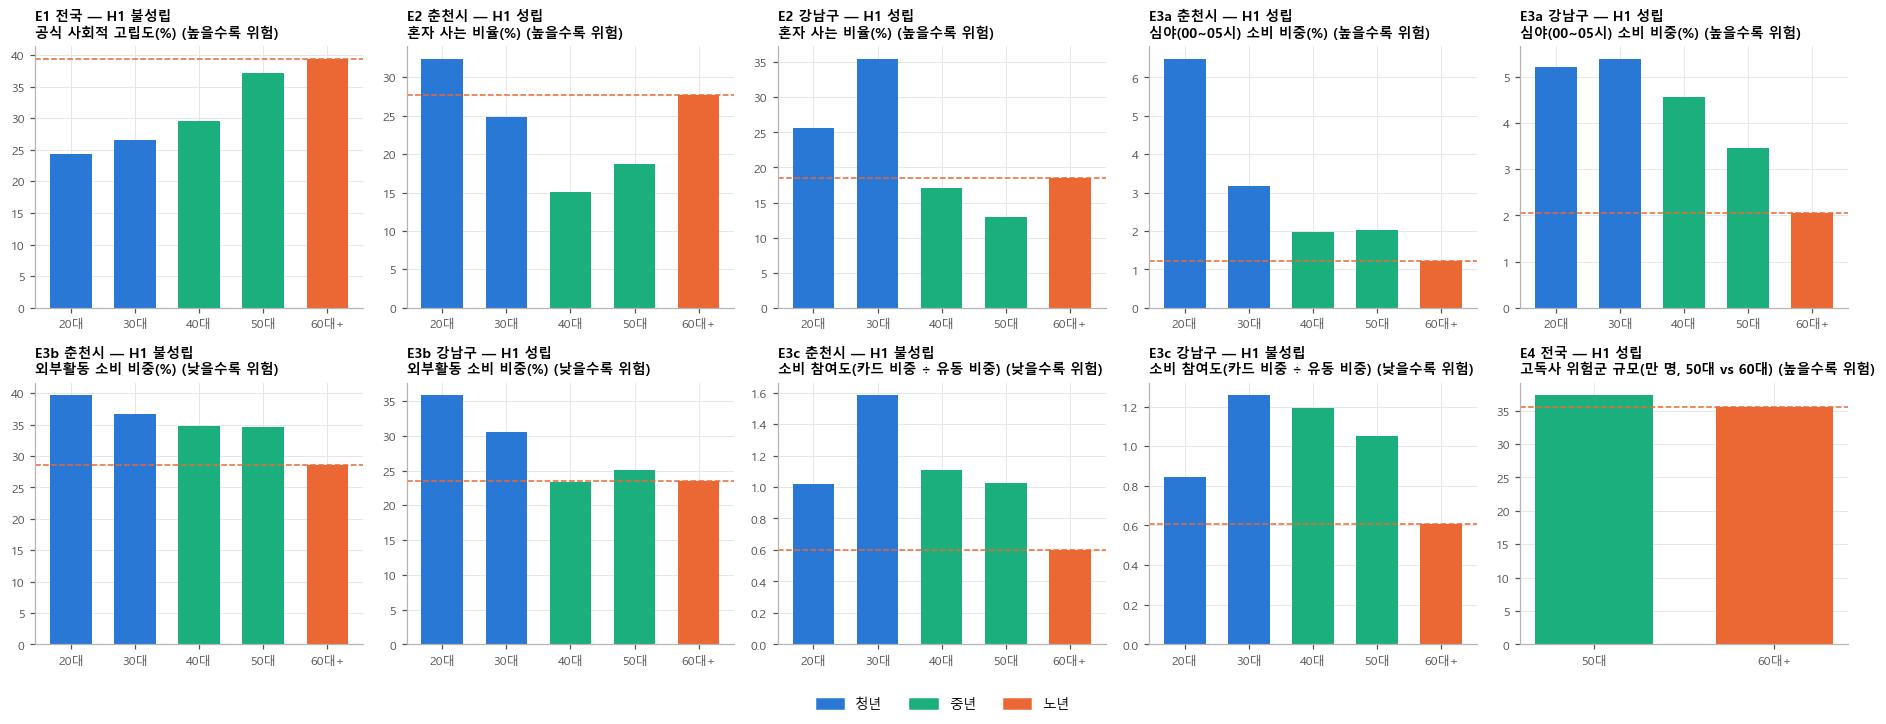

In [4]:
keys = list(TAB.index)
fig, axes = plt.subplots(2, 5, figsize=(17, 6.6))
for ax, key in zip(axes.flat, keys):
    r = TAB.loc[key].dropna(); x = np.arange(len(r))
    ax.bar(x, r.values, color=[STAGE_C[STAGE[a]] for a in r.index], width=.65)
    ax.axhline(r['60대+'], color=STAGE_C['노년'], lw=1, ls='--')
    ok = J[(J['지표'] == key[0]) & (J['지역'] == key[1])]['H1 성립'].iloc[0]
    ax.set_xticks(x, r.index, fontsize=8); ax.tick_params(axis='y', labelsize=8)
    ax.set_title(f"{key[0]} {key[1].replace('서울 ', '').replace('강원 ', '')} — {'H1 성립' if ok else 'H1 불성립'}\n{key[2]} ({key[3]} 위험)", fontsize=9)
for ax in axes.flat[len(keys):]: ax.axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in STAGE_C.values()]
fig.legend(handles, list(STAGE_C), loc='lower center', ncol=3, fontsize=9); plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

In [5]:
print('참고: 성별로 나눈 혼자 사는 비율(%) — 남녀 모두에서 같은 패턴인지')
display(alone_sex.unstack('연령5').reindex(columns=AGE5).round(1))

참고: 성별로 나눈 혼자 사는 비율(%) — 남녀 모두에서 같은 패턴인지


연령5         20대   30대   40대   50대  60대+
지역     성별                              
강원 춘천시 남   33.2  30.2  18.6  21.5  23.0
       여   31.5  19.0  11.7  16.0  31.5
서울 강남구 남   21.2  37.8  18.6  14.0  14.0
       여   29.5  33.4  15.7  11.9  22.2

## 5. 보조 — 고립 대응 서비스는 연령별로 어떻게 공급되나 (판정 제외)

> **왜** 위험이 청년에도 있다면 서비스도 그만큼 있는지 봅니다 (판정 제외).  
> **결과** 강남 청년 위험 인구는 약 6만 명으로 노년(3.4만)보다 많지만, 고립 직접 대응 서비스는 청년·노년 모두 4개입니다.


In [6]:
G = pd.read_csv(OUTD / '복지자원_공급공백_생애단계.csv')
G['위험 인구(이중 위험+행동형)'] = G['이중 위험 인구'] + G['행동형 인구']
display(G[['지역', '생애단계', '고립 직접', '관계·정서', '위험 인구(이중 위험+행동형)']])

,지역,생애단계,고립 직접,관계·정서,위험 인구(이중 위험+행동형)
0,서울 강남구,청년,4,44,59535
1,서울 강남구,중장년,3,44,57198
2,서울 강남구,노년,4,46,34399
3,강원 춘천시,청년,2,41,20461
4,강원 춘천시,중장년,1,42,28982
5,강원 춘천시,노년,2,44,31262


## 6. 왜 04의 유형 비중은 근거가 될 수 없나 (확인)

> **왜** 근거에서 뺀 지표가 왜 순환인지 숫자로 확인합니다.  
> **결과** H 상위 1/3 비중이 연령마다 30~39%로 비슷합니다. 설계상 당연한 결과라 연령 비교 근거가 될 수 없습니다.


In [7]:
R = pd.read_csv(OUTD / '위험도_2축_강남_춘천_동x성x연령.csv')
def top_share(g, col):                               # 지역 안 상위 1/3(인구 가중)에 드는 인구 비중
    return g.groupby('연령5').apply(lambda x: (x[col] >= R.loc[g.index, col].quantile(2 / 3)).mean() * 100)
chk = pd.concat({reg: top_share(R[R['지역'] == reg], '적용 H') for reg in MAIN}, axis=1).reindex(AGE5)
print("행동 고립 H가 지역 상위 1/3에 드는 집단 비중(%) — 연령마다 비슷하게 나오는 것은 설계 때문"); display(chk.round(1))

행동 고립 H가 지역 상위 1/3에 드는 집단 비중(%) — 연령마다 비슷하게 나오는 것은 설계 때문


,서울 강남구,강원 춘천시
연령5,,
20대,38.6,36.0
30대,31.8,30.0
40대,36.4,34.0
50대,34.1,38.0
60대+,29.5,34.0


## 7. 요약

> **왜** 판정과 한계를 정리합니다.  
> **결과** 고립의 종류가 연령마다 다르다는 해석과, 심야 지표를 빼도 판정이 같다는 점을 적었습니다.


### 판정: **부분 지지** (판정 지표 10개 중 6개에서 H1 성립)
청년·중년에서도 노년과 같거나 더 높은 고립 위험 요인이 분명히 있습니다. 그래서 "고립은 노년에 집중된다"(H0)는 기각됩니다. 다만 모든 지표에서 그런 것은 아니어서, 사전에 정한 '지지' 기준(7개 이상)에는 하나 모자랐습니다.

| 결과 | 지표 | 내용 |
|---|---|---|
| **H1 성립** (청년·중년 ≥ 노년) | 혼자 사는 비율 (두 지역) | 춘천 20대 32.4% > 60대+ 27.7% / 강남 30대 35.5%, 20대 25.6% > 60대+ 18.5% |
| | 심야 소비 비중 (두 지역) | 20~50대 모두 60대+보다 높음 (춘천 20대 6.5% vs 1.2%, 강남 30대 5.4% vs 2.1%) |
| | 외부활동 소비 비중 (강남) | 40대 23.4% ≈ 60대+ 23.5% (사실상 같음) |
| | 고독사 위험군 규모 (전국) | 50대 37.3만 명 > 60대 35.5만 명 |
| **H1 불성립** (노년이 가장 위험) | 공식 사회적 고립도 | 나이가 들수록 높아져 60대+ 39.4%가 최고 (20대 24.4%) |
| | 외부활동 소비 비중 (춘천) | 60대+ 28.6%가 가장 낮음 |
| | 소비 참여도 (두 지역) | 60대+ 0.60~0.61로 가장 낮음 |

### 해석
1. **고립의 '종류'가 연령마다 다릅니다.**
   - 노년: 관계·활동의 '양'(도움받을 사람, 소비 참여)에서 가장 취약합니다.
   - 청년: '혼자 사는 구조'와 '생활 리듬'(심야 활동)에서 노년 이상입니다.
   - 중년: 고독사 위험군 규모(50대)가 가장 크고, 강남 40대의 외부활동은 노년 수준입니다.
2. 그래서 연령 하나로 위험을 줄 세우면 청년·중년이 빠집니다. 04에서 **행동 고립 × 사회경제 취약 2축**과 **생애단계 안 순위**를 따로 둔 이유가 여기서 확인됩니다.
3. **공급 쪽(보조)**: 강남 청년의 위험 인구(이중 위험+행동형 약 6만 명)는 노년(3.4만 명)보다 많습니다. 그런데 고립에 직접 대응하는 서비스는 청년 4개, 노년 4개로 같습니다.

### 한계
- **심야 소비는 약한 신호입니다.** 생활 리듬이나 직업 차이일 수 있습니다. 심야 지표를 빼면 8개 중 4개 성립으로, 판정은 여전히 '부분 지지'입니다.
- **카드 지표의 집계 기준**: 가맹점 위치 기준이라 거주민만의 소비가 아닙니다.
- **고독사 위험군 출처**: 보건복지부 「제1차 고독사 예방 기본계획」(2023.5.18) 14쪽의 전국 추정치입니다. 사전 등록 때는 70대 이상 값이 없다고 적었지만 원문에는 70대 이상 21만 명(1인 가구의 16.2%)이 있습니다. 10세 폭이 같은 50대·60대 비교는 사전 등록 그대로이고, 1인 가구 대비 비율로 봐도 50대 33.9% > 60대 30.2% > 70대 이상 16.2%라 판정은 같습니다.
- **공식 고립도 출처**: 국가지표체계 사회적 고립도(국가데이터처, 2026-01-05 갱신)에서 전체 33.0%, 19~29세 24.4%, 60세 이상 39.4%를 원문으로 확인했습니다. 30·40·50대 값(26.5·29.5·37.2%)은 원문 페이지에 없어 보도 인용입니다. 판정(노년이 가장 높음)은 60세 이상 39.4%가 다른 연령보다 높다는 데서 나오며, 30~50대 값이 원문으로 확인되지 않은 한계가 있습니다.
- **강남 외부활동은 동률 수준**입니다(차이 0.1%p). 방향을 단정하기 어렵습니다.
- **04의 유형 비중은 근거에서 뺐습니다.** H 상위 1/3 비중이 연령마다 30~39%로 비슷하게 나오는데, 이는 설계상 당연한 결과라서입니다(6절).